# Breast Cancer Classification Using Machine Learning and Neural Networks

## Introduction

This project develops machine-learning models to classify breast tumours as benign or malignant using the UCI Breast Cancer Wisconsin Diagnostic dataset. The dataset contains measurements calculated from digitized images of fine-needle aspirates of breast masses.

The project compares Logistic Regression, Support Vector Machine, Random Forest and a Neural Network. The models are evaluated using accuracy, precision, recall, F1-score, ROC-AUC and a confusion matrix. Special attention is given to recall because incorrectly classifying a malignant tumour as benign may have serious consequences.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, GridSearchCV

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
RANDOM_STATE = 42

In [42]:
from google.colab import files

uploaded = files.upload()

Saving wdbc.data to wdbc (1).data


In [43]:
DATA_PATH = "wdbc.data"

In [44]:
feature_names = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points",
    "symmetry", "fractal_dimension"
]

columns = ["id", "diagnosis"]

for measurement in ["mean", "se", "worst"]:
    for feature in feature_names:
        columns.append(f"{measurement}_{feature}")

df = pd.read_csv(DATA_PATH, header=None, names=columns)

df.head()

,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [45]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (569, 32)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   mean_radius              569 non-null    float64
 3   mean_texture             569 non-null    float64
 4   mean_perimeter           569 non-null    float64
 5   mean_area                569 non-null    float64
 6   mean_smoothness          569 non-null    float64
 7   mean_compactness         569 non-null    float64
 8   mean_concavity           569 non-null    float64
 9   mean_concave_points      569 non-null    float64
 10  mean_symmetry            569 non-null    float64
 11  mean_fractal_dimension   569 non-null    float64
 12  se_radius                569 non-null    float64
 13  se_texture               569 non-null    float64
 14  s

In [46]:
df["diagnosis"].value_counts()

,count
diagnosis,
B,357
M,212


In [47]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
mean_radius,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
mean_texture,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
mean_perimeter,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
mean_area,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
mean_smoothness,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
mean_compactness,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
mean_concavity,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
mean_concave_points,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
mean_symmetry,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


In [48]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [49]:
df.isnull().sum().sum()

np.int64(0)

The dataset contains 569 observations and 32 columns. The columns include one identification number, one diagnosis variable and 30 numerical predictor variables. The diagnosis variable contains two classes: benign and malignant. The ID column is not a meaningful predictor, so it will be removed. The dataset contains no missing values and no duplicate observations.

In [50]:
df["target"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

df["target"].value_counts()

,count
target,
0,357
1,212


In [51]:
X = df.drop(columns=["id", "diagnosis", "target"])
y = df["target"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (569, 30)
Target: (569,)


The diagnosis variable is converted into a binary target where 0 represents benign and 1 represents malignant. The ID column is removed because it only identifies each record and does not describe tumour characteristics.

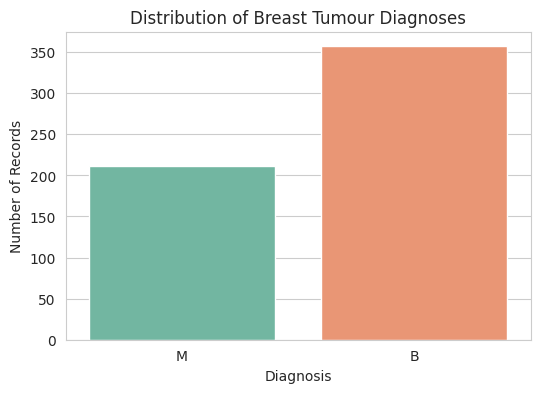

In [52]:
plt.figure(figsize=(6, 4))

sns.countplot(
    x=df["diagnosis"],
    hue=df["diagnosis"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Breast Tumour Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.show()

In [53]:
correlations = (
    df.drop(columns=["id", "diagnosis"])
      .corr()["target"]
      .drop("target")
      .abs()
      .sort_values(ascending=False)
)

correlations.head(10)

,target
worst_concave_points,0.793566
worst_perimeter,0.782914
mean_concave_points,0.776614
worst_radius,0.776454
mean_perimeter,0.742636
worst_area,0.733825
mean_radius,0.730029
mean_area,0.708984
mean_concavity,0.696360
worst_concavity,0.659610


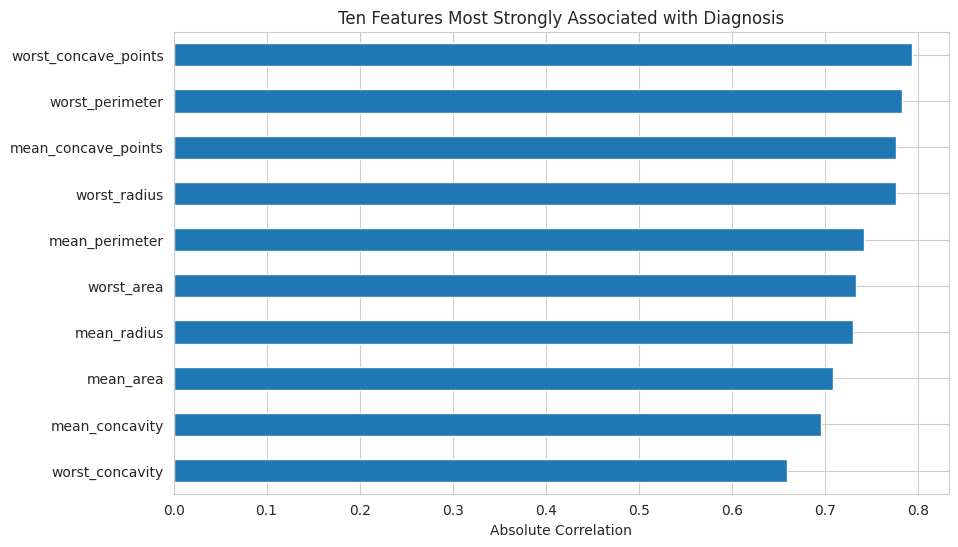

In [54]:
plt.figure(figsize=(10, 6))

correlations.head(10).sort_values().plot(kind="barh")

plt.title("Ten Features Most Strongly Associated with Diagnosis")
plt.xlabel("Absolute Correlation")
plt.show()

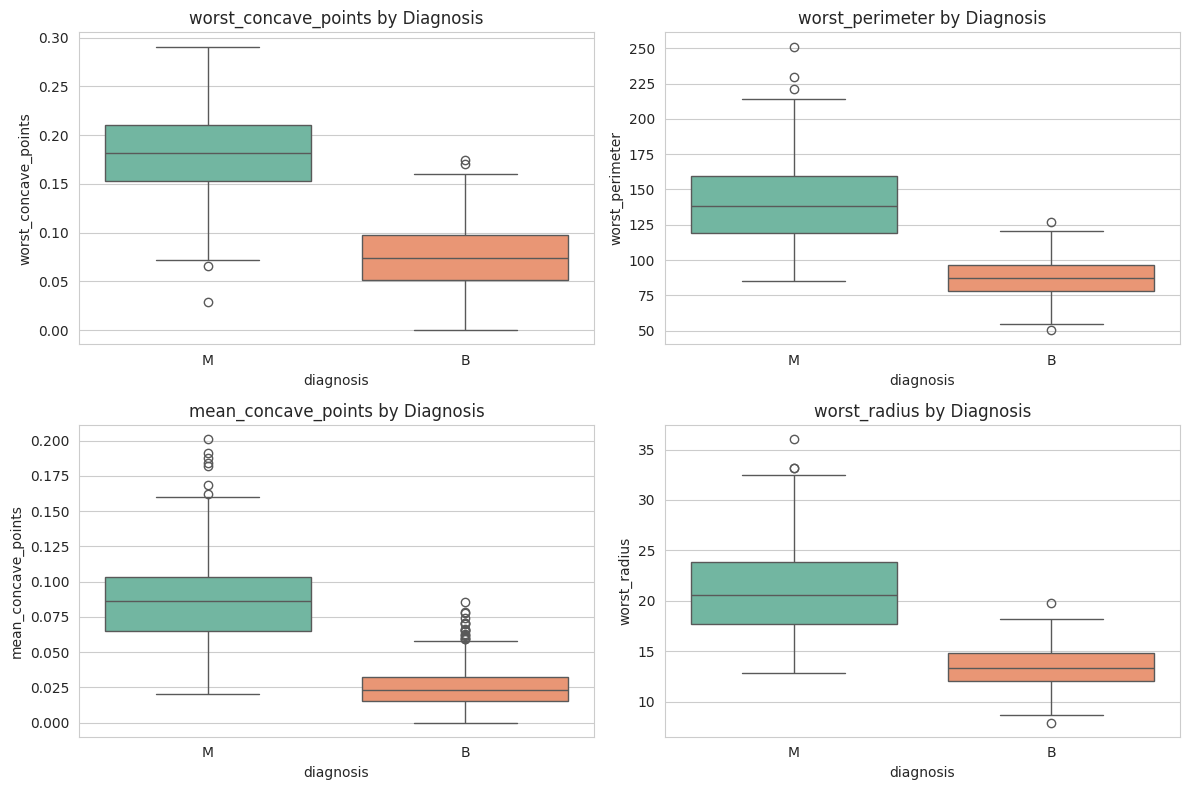

In [55]:
top_features = correlations.head(4).index.tolist()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

for i, feature in enumerate(top_features):
    sns.boxplot(
        data=df,
        x="diagnosis",
        y=feature,
        hue="diagnosis",
        palette="Set2",
        legend=False,
        ax=axes[i]
    )
    axes[i].set_title(f"{feature} by Diagnosis")

plt.tight_layout()
plt.show()

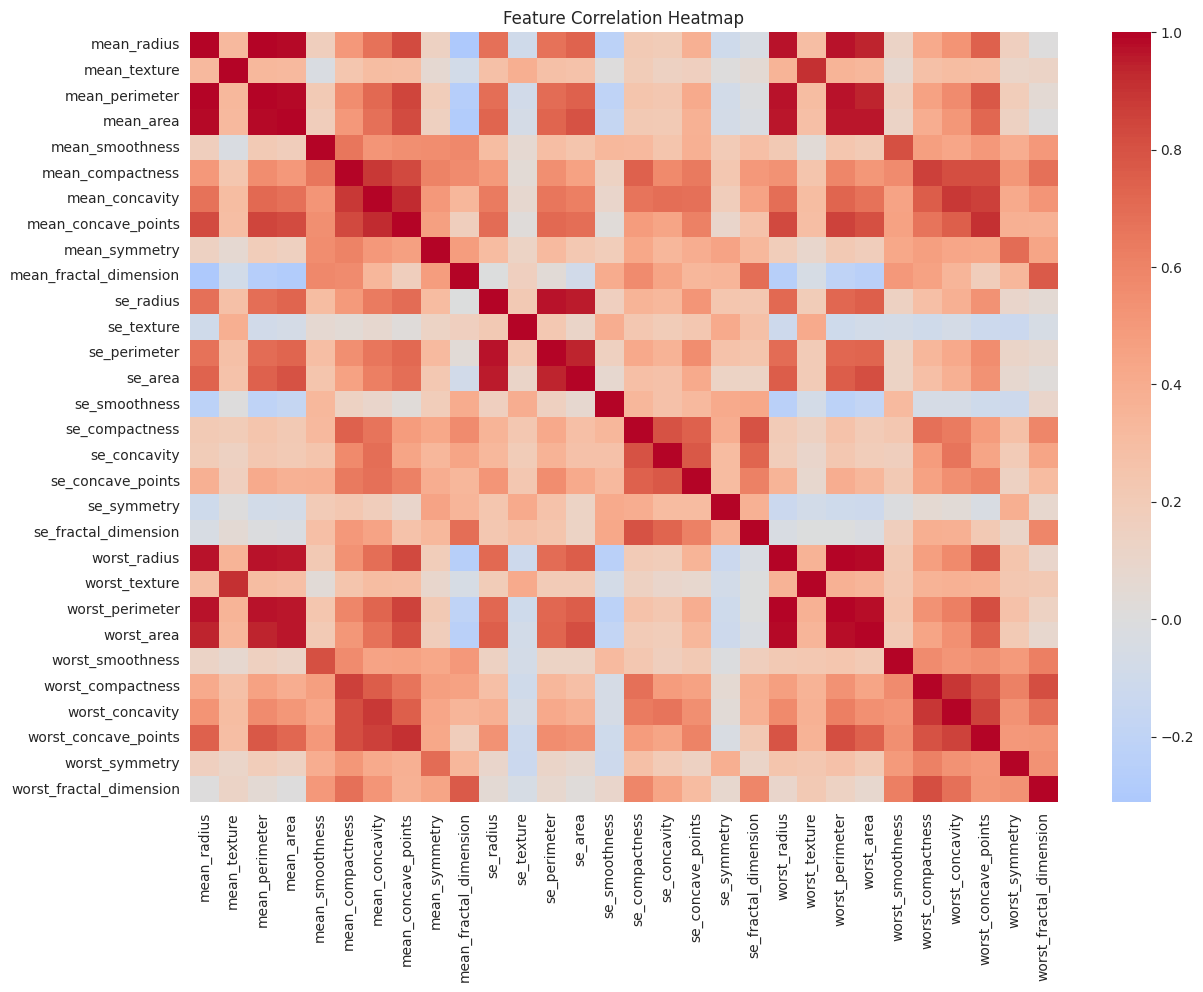

In [56]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

The exploratory analysis shows that several tumour-size and tumour-shape features are strongly associated with diagnosis. Features such as worst radius, worst perimeter, worst area and worst concave points show clear differences between benign and malignant cases. Several features are also highly correlated with each other, so scaling and model comparison are important.

In [57]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (398, 30)
Validation set: (85, 30)
Test set: (86, 30)


In [58]:
print("Training distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest distribution:")
print(y_test.value_counts(normalize=True))

Training distribution:
target
0    0.628141
1    0.371859
Name: proportion, dtype: float64

Validation distribution:
target
0    0.623529
1    0.376471
Name: proportion, dtype: float64

Test distribution:
target
0    0.627907
1    0.372093
Name: proportion, dtype: float64


The data is divided into 70% training data, 15% validation data and 15% test data. Stratified sampling is used so that the proportions of benign and malignant cases remain similar in all three sets. The training set is used for model development, the validation set is used for model selection and the test set is reserved for final evaluation.

In [59]:
def calculate_metrics(model_name, y_true, y_pred, y_probability):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_probability)
    }

In [60]:
logistic_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

In [61]:
logistic_parameters = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

logistic_search = GridSearchCV(
    logistic_pipeline,
    logistic_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

logistic_search.fit(X_train, y_train)

print("Best parameters:", logistic_search.best_params_)
print("Best cross-validation F1-score:", logistic_search.best_score_)

Best parameters: {'model__C': 1, 'model__solver': 'lbfgs'}
Best cross-validation F1-score: 0.9756721581862312


In [62]:
logistic_val_probability = logistic_search.predict_proba(X_val)[:, 1]
logistic_val_prediction = logistic_search.predict(X_val)

print(classification_report(
    y_val,
    logistic_val_prediction,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        53
   Malignant       1.00      0.91      0.95        32

    accuracy                           0.96        85
   macro avg       0.97      0.95      0.96        85
weighted avg       0.97      0.96      0.96        85



In [63]:
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SVC(probability=True))
])

svm_parameters = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", "auto"],
    "model__kernel": ["linear", "rbf"]
}

svm_search = GridSearchCV(
    svm_pipeline,
    svm_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

svm_search.fit(X_train, y_train)

print("Best parameters:", svm_search.best_params_)
print("Best cross-validation F1-score:", svm_search.best_score_)

Best parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Best cross-validation F1-score: 0.9614753024104281


In [64]:
svm_val_probability = svm_search.predict_proba(X_val)[:, 1]
svm_val_prediction = svm_search.predict(X_val)

print(classification_report(
    y_val,
    svm_val_prediction,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.93      1.00      0.96        53
   Malignant       1.00      0.88      0.93        32

    accuracy                           0.95        85
   macro avg       0.96      0.94      0.95        85
weighted avg       0.96      0.95      0.95        85



In [65]:
random_forest_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE
    ))
])

random_forest_parameters = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__class_weight": [None, "balanced"]
}

random_forest_search = GridSearchCV(
    random_forest_pipeline,
    random_forest_parameters,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

random_forest_search.fit(X_train, y_train)

print("Best parameters:", random_forest_search.best_params_)
print("Best cross-validation F1-score:", random_forest_search.best_score_)

Best parameters: {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Best cross-validation F1-score: 0.9282062621286761


In [66]:
rf_val_probability = random_forest_search.predict_proba(X_val)[:, 1]
rf_val_prediction = random_forest_search.predict(X_val)

print(classification_report(
    y_val,
    rf_val_prediction,
    target_names=["Benign", "Malignant"]
))

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        53
   Malignant       1.00      0.91      0.95        32

    accuracy                           0.96        85
   macro avg       0.97      0.95      0.96        85
weighted avg       0.97      0.96      0.96        85



In [67]:
nn_imputer = SimpleImputer(strategy="median")
nn_scaler = StandardScaler()

X_train_nn = nn_imputer.fit_transform(X_train)
X_val_nn = nn_imputer.transform(X_val)
X_test_nn = nn_imputer.transform(X_test)

X_train_nn = nn_scaler.fit_transform(X_train_nn)
X_val_nn = nn_scaler.transform(X_val_nn)
X_test_nn = nn_scaler.transform(X_test_nn)

In [68]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(RANDOM_STATE)

In [69]:
neural_network = Sequential([
    Input(shape=(X_train_nn.shape[1],)),
    Dense(32, activation="relu"),
    Dropout(0.20),
    Dense(16, activation="relu"),
    Dropout(0.20),
    Dense(1, activation="sigmoid")
])

neural_network.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

neural_network.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [70]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = neural_network.fit(
    X_train_nn,
    y_train,
    validation_data=(X_val_nn, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.6156 - loss: 0.9718 - val_accuracy: 0.6118 - val_loss: 0.7631
Epoch 2/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6558 - loss: 0.7057 - val_accuracy: 0.6706 - val_loss: 0.5467
Epoch 3/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6910 - loss: 0.5382 - val_accuracy: 0.8000 - val_loss: 0.4323
Epoch 4/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7965 - loss: 0.4547 - val_accuracy: 0.8941 - val_loss: 0.3583
Epoch 5/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8593 - loss: 0.4035 - val_accuracy: 0.9412 - val_loss: 0.3099
Epoch 6/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8869 - loss: 0.3347 - val_accuracy: 0.9529 - val_loss: 0.2713
Epoch 7/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9070 - loss: 0.3032 - val_accuracy: 0.9529 - val_loss: 0.2379
Epoch 8/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9322 - loss: 0.2815 - val_accuracy: 0.9

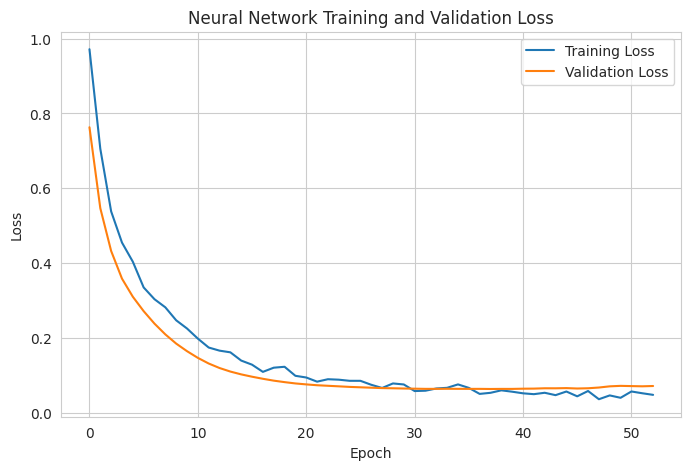

In [71]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

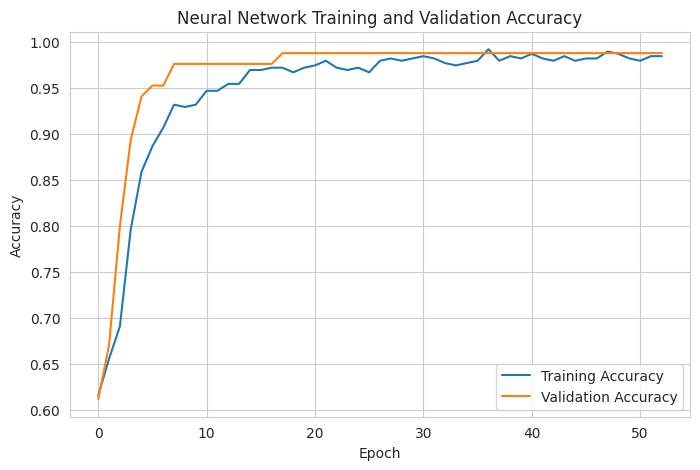

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Neural Network Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [73]:
nn_val_probability = neural_network.predict(X_val_nn).ravel()
nn_val_prediction = (nn_val_probability >= 0.5).astype(int)

print(classification_report(
    y_val,
    nn_val_prediction,
    target_names=["Benign", "Malignant"]
))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
              precision    recall  f1-score   support

      Benign       0.98      1.00      0.99        53
   Malignant       1.00      0.97      0.98        32

    accuracy                           0.99        85
   macro avg       0.99      0.98      0.99        85
weighted avg       0.99      0.99      0.99        85



In [74]:
validation_results = []

validation_results.append(
    calculate_metrics(
        "Logistic Regression",
        y_val,
        logistic_val_prediction,
        logistic_val_probability
    )
)

validation_results.append(
    calculate_metrics(
        "Support Vector Machine",
        y_val,
        svm_val_prediction,
        svm_val_probability
    )
)

validation_results.append(
    calculate_metrics(
        "Random Forest",
        y_val,
        rf_val_prediction,
        rf_val_probability
    )
)

validation_results.append(
    calculate_metrics(
        "Neural Network",
        y_val,
        nn_val_prediction,
        nn_val_probability
    )
)

validation_results_df = pd.DataFrame(validation_results)
validation_results_df.sort_values(
    by="F1-Score",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,Neural Network,0.988235,1.0,0.96875,0.984127,0.995283
0,Logistic Regression,0.964706,1.0,0.90625,0.950820,0.996462
2,Random Forest,0.964706,1.0,0.90625,0.950820,0.992925
1,Support Vector Machine,0.952941,1.0,0.87500,0.933333,0.995873


In [75]:
test_results = []

# Logistic Regression
logistic_test_probability = logistic_search.predict_proba(X_test)[:, 1]
logistic_test_prediction = logistic_search.predict(X_test)

test_results.append(
    calculate_metrics(
        "Logistic Regression",
        y_test,
        logistic_test_prediction,
        logistic_test_probability
    )
)

# SVM
svm_test_probability = svm_search.predict_proba(X_test)[:, 1]
svm_test_prediction = svm_search.predict(X_test)

test_results.append(
    calculate_metrics(
        "Support Vector Machine",
        y_test,
        svm_test_prediction,
        svm_test_probability
    )
)

# Random Forest
rf_test_probability = random_forest_search.predict_proba(X_test)[:, 1]
rf_test_prediction = random_forest_search.predict(X_test)

test_results.append(
    calculate_metrics(
        "Random Forest",
        y_test,
        rf_test_prediction,
        rf_test_probability
    )
)

# Neural Network
nn_test_probability = neural_network.predict(X_test_nn).ravel()
nn_test_prediction = (nn_test_probability >= 0.5).astype(int)

test_results.append(
    calculate_metrics(
        "Neural Network",
        y_test,
        nn_test_prediction,
        nn_test_probability
    )
)

test_results_df = pd.DataFrame(test_results)

test_results_df.sort_values(
    by="F1-Score",
    ascending=False
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,Neural Network,1.000000,1.00000,1.00000,1.000000,1.000000
0,Logistic Regression,0.976744,0.96875,0.96875,0.968750,0.998843
2,Random Forest,0.976744,1.00000,0.93750,0.967742,0.997685
1,Support Vector Machine,0.965116,1.00000,0.90625,0.950820,1.000000


In [76]:
test_results_df.to_csv(
    "breast_cancer_model_comparison.csv",
    index=False
)

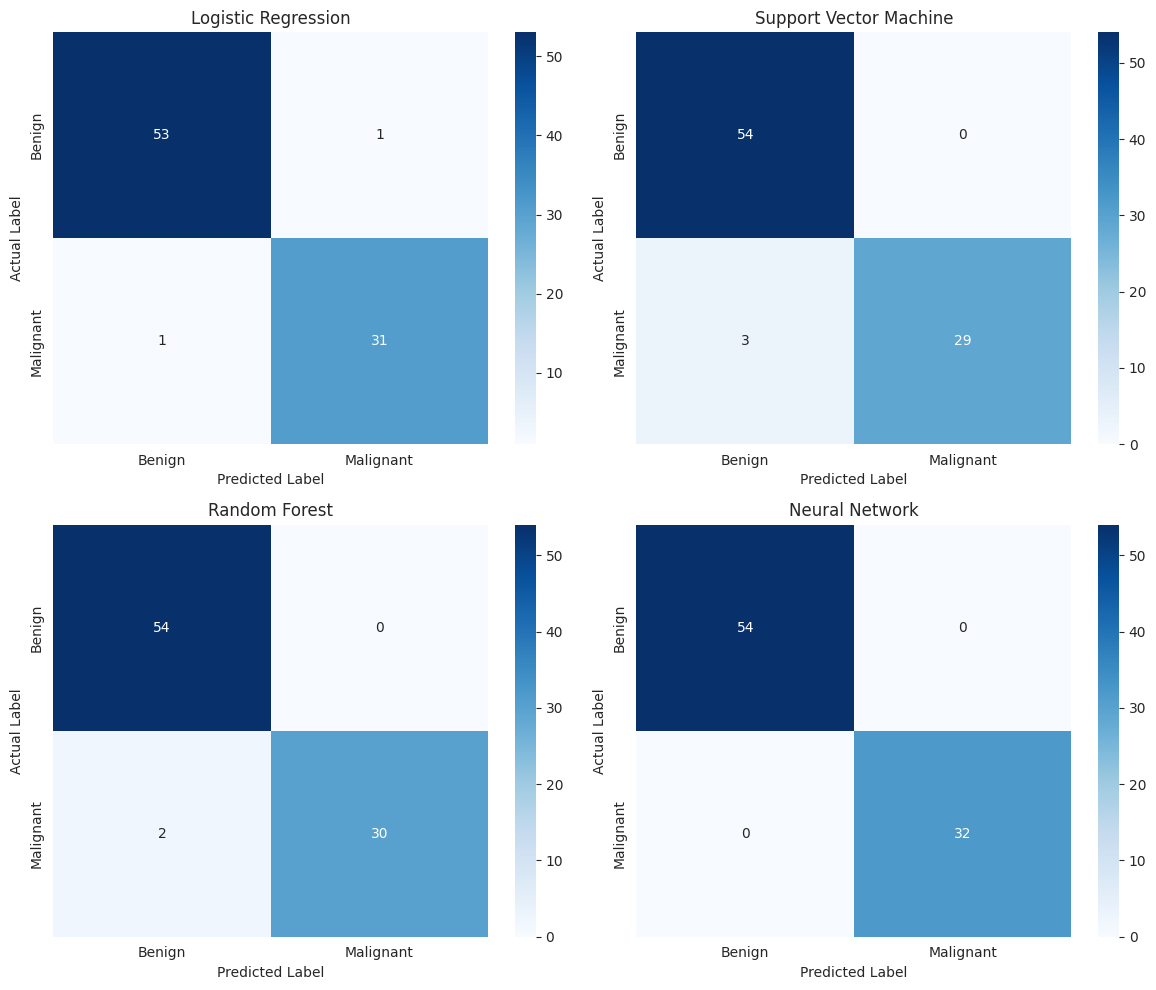

In [77]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

model_predictions = {
    "Logistic Regression": logistic_test_prediction,
    "Support Vector Machine": svm_test_prediction,
    "Random Forest": rf_test_prediction,
    "Neural Network": nn_test_prediction
}

for ax, (name, prediction) in zip(axes.ravel(), model_predictions.items()):
    cm = confusion_matrix(y_test, prediction)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

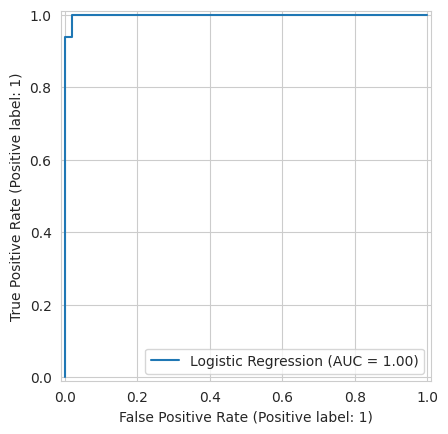

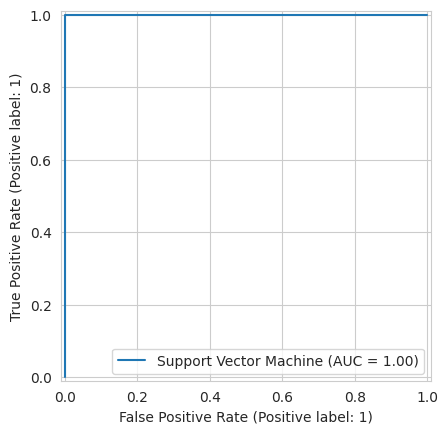

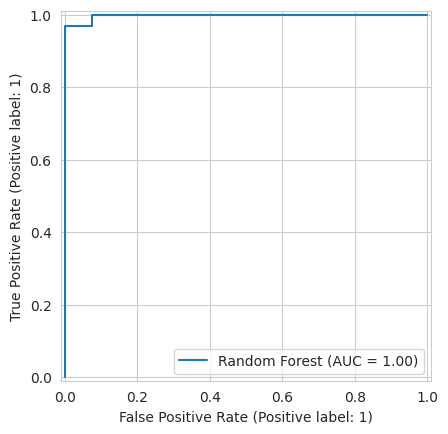

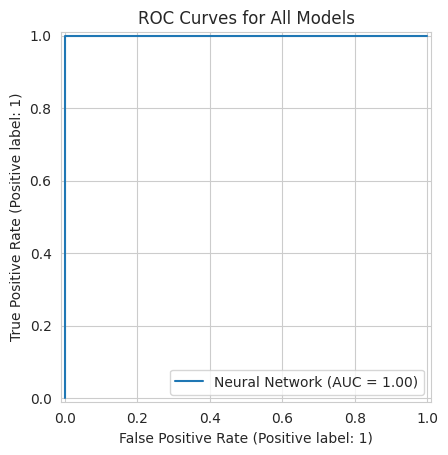

In [78]:
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    logistic_test_probability,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    svm_test_probability,
    name="Support Vector Machine"
)

RocCurveDisplay.from_predictions(
    y_test,
    rf_test_probability,
    name="Random Forest"
)

RocCurveDisplay.from_predictions(
    y_test,
    nn_test_probability,
    name="Neural Network"
)

plt.title("ROC Curves for All Models")
plt.show()

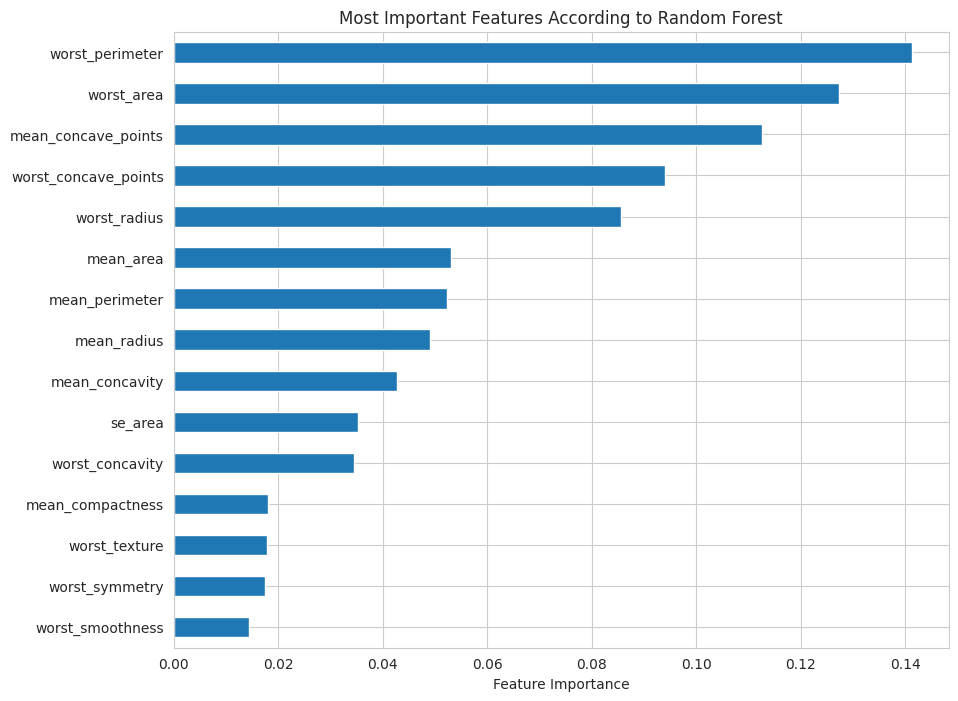

In [79]:
rf_model = random_forest_search.best_estimator_.named_steps["model"]

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))

feature_importance.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Most Important Features According to Random Forest")
plt.xlabel("Feature Importance")
plt.show()

The Random Forest feature-importance analysis identifies the tumour measurements that contribute most strongly to classification. These features can be compared with the correlation analysis to determine whether the most important predictors are also strongly associated with the target variable.

## Conclusion

This project developed and evaluated four classification models for predicting whether breast tumours are benign or malignant. Logistic Regression, Support Vector Machine, Random Forest and a Neural Network were trained using the UCI Breast Cancer Wisconsin Diagnostic dataset.

The models were evaluated using accuracy, precision, recall, F1-score and ROC-AUC. The final model should be selected based not only on accuracy but also on recall because detecting malignant tumours is particularly important. The results show the strengths and weaknesses of traditional machine-learning methods compared with the neural network.

Future improvements could include testing additional ensemble models, applying systematic feature selection, tuning classification thresholds and using a larger external dataset for independent validation.